# Лабораторная работа №2. Локальные методы выделения контуров

**Цель работы:** изучить и экспериментально исследовать методы выделения контуров на изображениях с помощью линейной локальной обработки «окном».

Исследуются методы:

1. простой градиентный метод (три способа вычисления модуля градиента);
2. оператор Лапласа (традиционная, диагональная и комбинированная маски);
3. оператор Прюитт;
4. согласованный оператор Лапласа.

Обработка выполняется в два этапа: выделение перепадов яркости -> промежуточное изображение `e(m,n)`, затем пороговая обработка -> бинарное изображение контуров.

**Способ обработки границ изображения.** При выходе окна за пределы изображения берётся значение ближайшего определённого элемента: для двумерной корреляции — зеркальное отражение (`boundary='symm'` в `scipy.signal.correlate2d`), для дискретных разностей — дублирование края (`np.pad(..., mode='edge')`). Такой выбор не создаёт ложных контуров вдоль рамки изображения (в отличие от заполнения нулями).

**Способ отображения знаковых результатов.** Отклики лапласиана и дискретных разностей принимают и положительные, и отрицательные значения. При визуализации к ним прибавляется 128 (отрицательная часть не отбрасывается). Тёмные промежуточные изображения дополнительно контрастируются (`vmax` по 99.9-му перцентилю) — только при показе, обработка ведётся по исходным значениям.

## 1. Загрузка исходного изображения

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate2d
from PIL import Image

размер: (880, 1300) | диапазон яркости: 0.0 - 254.77200000000002


(np.float64(-0.5), np.float64(1299.5), np.float64(879.5), np.float64(-0.5))

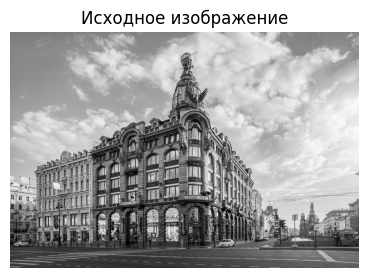

In [56]:
IMAGE_PATH = 'image.png'

RED_WEIGHT = 0.299
GREEN_WEIGHT = 0.587
BLUE_WEIGHT = 0.114

RGBA_CHANNELS = 4
RGB_CHANNELS = 3

MIN_BRIGHTNESS = 0
MAX_BRIGHTNESS = 255

img = np.asarray(Image.open(IMAGE_PATH)).astype(np.float64)

if img.ndim == 3:
    if img.shape[2] == RGBA_CHANNELS:
        img = img[..., :RGB_CHANNELS]

    img = (
        RED_WEIGHT * img[..., 0]
        + GREEN_WEIGHT * img[..., 1]
        + BLUE_WEIGHT * img[..., 2]
    )

print('размер:', img.shape, '| диапазон яркости:', img.min(), '-', img.max())

plt.figure(figsize=(4.5, 4.5))
plt.imshow(
    img,
    cmap='gray',
    vmin=MIN_BRIGHTNESS,
    vmax=MAX_BRIGHTNESS
)
plt.title('Исходное изображение')
plt.axis('off')

## 2. Вспомогательные функции

Перемещение окна по изображению реализуется функцией двумерной корреляции `scipy.signal.correlate2d`; коэффициенты каждой маски задаются явно в соответствующих разделах.

Порог $f_0$ выбирается по гистограмме промежуточного изображения: берётся уровень отклика на самые сильные перепады (99.9-й перцентиль $x_{0.999}$) и от него откладывается доля $\alpha=0.4$: $f_0 = \alpha \cdot x_{0.999}$. Выбранное значение $f_0$ выводится на экран и отмечается на гистограмме красной линией; при необходимости его можно скорректировать, визуально оценивая результат.

In [57]:
THRESHOLD_LEVEL = 0.999   # перцентиль уровня отклика на сильные перепады
THRESHOLD_SCALE = 0.4     # доля от этого уровня, принятая за порог (подобрана по гистограммам)


def apply_mask(image, mask):
    """Линейная обработка окном: двумерная корреляция изображения с маской.

    Перемещение окна выполняет correlate2d. Границы изображения:
    зеркальное отражение (boundary='symm'), т.е. за пределами берутся
    значения ближайших определённых элементов."""
    return correlate2d(image, mask, mode='same', boundary='symm')


def pick_threshold(e, level=THRESHOLD_LEVEL, scale=THRESHOLD_SCALE):
    """Выбор порога по гистограмме: f0 = scale * перцентиль(level).
    x_level - уровень отклика на самые сильные перепады изображения."""
    return float(scale * np.quantile(e, level))


def binarize(e, f0):
    """Пороговая обработка: 255 - контур, 0 - фон."""
    return np.where(e >= f0, 255, 0).astype(np.uint8)


def hist_and_threshold(e, f0, title, bins=128):
    """Гистограмма промежуточного изображения с отмеченным порогом f0."""
    plt.figure(figsize=(6, 3))
    plt.hist(e.ravel(), bins=bins)
    plt.axvline(f0, color='red', label=f'f0 = {f0:.1f}')
    plt.legend(); plt.title(title)
    plt.xlabel('значение отклика'); plt.ylabel('число пикселей')


def show(image, title, signed=False):
    """Показ одного изображения.
    signed=True: результат со знаком, показывается как image + 128;
    uint8: бинарное изображение; иначе: контрастирование по 99.9 перцентилю."""
    if signed:
        disp, vmax = np.clip(image + 128, 0, 255), 255
    elif image.dtype == np.uint8:
        disp, vmax = image, 255
    else:
        disp, vmax = image, np.percentile(image, 99.9)
    plt.figure(figsize=(4.5, 4.5))
    plt.imshow(disp, cmap='gray', vmin=0, vmax=vmax)
    plt.title(title); plt.axis('off')


def show_grid(images, titles, suptitle=None, ncols=None, signed=False):
    """Показ набора изображений (цикл используется только для вывода картинок)."""
    n = len(images)
    ncols = ncols or n
    nrows = -(-n // ncols)
    fig, ax = plt.subplots(nrows, ncols, figsize=(3.7 * ncols + 1, 3.9 * nrows))
    ax = np.atleast_1d(ax).ravel()
    for a, im, t in zip(ax, images, titles):
        if signed:
            d, vm = np.clip(im + 128, 0, 255), 255
        elif im.dtype == np.uint8:
            d, vm = im, 255
        else:
            d, vm = im, np.percentile(im, 99.9)
        a.imshow(d, cmap='gray', vmin=0, vmax=vm)
        a.set_title(t, fontsize=9); a.axis('off')
    for a in ax[n:]:
        a.axis('off')
    if suptitle:
        fig.suptitle(suptitle)

## 3. Простой градиентный метод

Частные производные заменяются дискретными разностями:

$$s_1 = f(m,n) - f(m-1,n), \qquad s_2 = f(m,n) - f(m,n-1).$$

На границе изображения берётся ближайшее определённое значение (`mode='edge'`), поэтому разности на краю равны нулю и ложных контуров вдоль рамки не возникает.

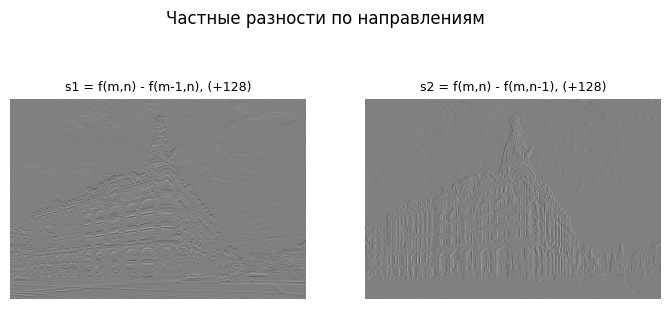

In [58]:
# Дискретные разности (векторно, без циклов)
fp = np.pad(img, 1, mode='edge')
s1 = fp[1:-1, 1:-1] - fp[:-2, 1:-1]    # s1 = f(m,n) - f(m-1,n), по вертикали
s2 = fp[1:-1, 1:-1] - fp[1:-1, :-2]    # s2 = f(m,n) - f(m,n-1), по горизонтали

show_grid([s1, s2], ['s1 = f(m,n) - f(m-1,n), (+128)',
                     's2 = f(m,n) - f(m,n-1), (+128)'],
          'Частные разности по направлениям', signed=True)

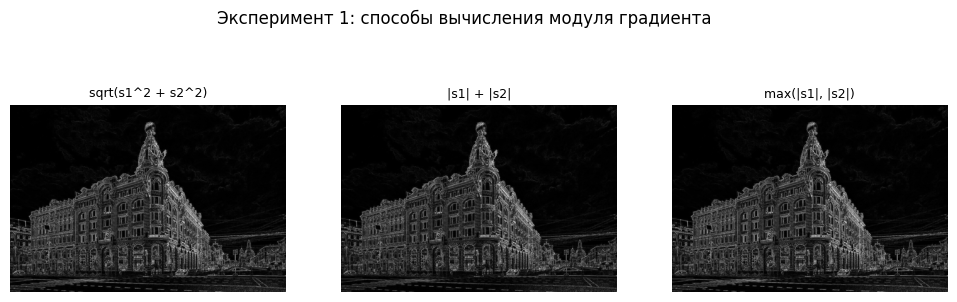

In [59]:
def grad_magnitude(image):
    """Простой градиентный метод: дискретные разности + точный модуль градиента."""
    fp_ = np.pad(image, 1, mode='edge')
    d1 = fp_[1:-1, 1:-1] - fp_[:-2, 1:-1]
    d2 = fp_[1:-1, 1:-1] - fp_[1:-1, :-2]
    return np.sqrt(d1 ** 2 + d2 ** 2)


# Три способа вычисления модуля градиента
e_exact = np.sqrt(s1 ** 2 + s2 ** 2)             # точное значение
e_sum = np.abs(s1) + np.abs(s2)                   # приближение |s1| + |s2|
e_max = np.maximum(np.abs(s1), np.abs(s2))       # приближение max(|s1|, |s2|)

show_grid([e_exact, e_sum, e_max],
          ['sqrt(s1^2 + s2^2)', '|s1| + |s2|', 'max(|s1|, |s2|)'],
          'Эксперимент 1: способы вычисления модуля градиента')

**Эксперимент 1, наблюдения.** Точное значение $\sqrt{s_1^2+s_2^2}$ и сумма модулей $|s_1|+|s_2|$ дают похожие контуры; сумма модулей систематически завышает отклик (для границы, идущей под 45°, ровно в $\sqrt{2}$ раза), поэтому контуры выглядят чуть «толще» и ярче. Оценка $\max(|s_1|,|s_2|)$, наоборот, занижает отклик на диагональных границах (до $1/\sqrt{2}$ раза) — диагональные контуры получаются слабее, зато горизонтальные и вертикальные передаются без искажения масштаба.

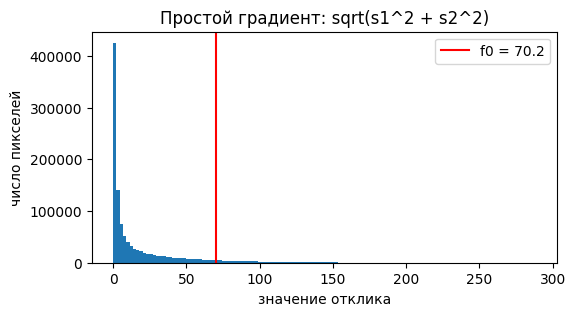

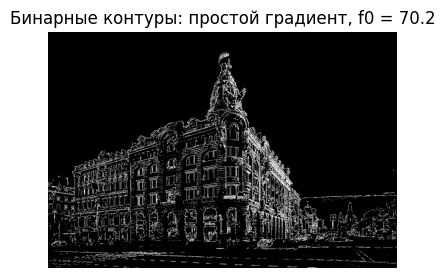

In [60]:
# Гистограмма промежуточного изображения, выбор порога, пороговая обработка
f0_grad = pick_threshold(e_exact)
hist_and_threshold(e_exact, f0_grad, 'Простой градиент: sqrt(s1^2 + s2^2)')
b_grad = binarize(e_exact, f0_grad)
show(b_grad, f'Бинарные контуры: простой градиент, f0 = {f0_grad:.1f}')

**Функция поэлементного преобразования.** Пороговая обработка реализуется ступенчатой функцией $g(e) = 255$ при $e \geq f_0$ и $g(e) = 0$ иначе (светлые линии контуров на тёмном фоне). График функции показан ниже; она одинакова для всех исследуемых методов, меняется только порог $f_0$.


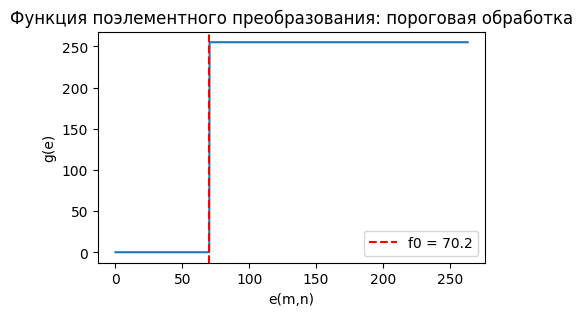

In [61]:
# График функции поэлементного преобразования для пороговой обработки
ex = np.linspace(0, np.percentile(e_exact, 99.9) * 1.5, 1000)
plt.figure(figsize=(5, 3))
plt.plot(ex, binarize(ex, f0_grad))
plt.axvline(f0_grad, color='red', ls='--', label=f'f0 = {f0_grad:.1f}')
plt.xlabel('e(m,n)'); plt.ylabel('g(e)'); plt.legend()
plt.title('Функция поэлементного преобразования: пороговая обработка');


## 4. Оператор Лапласа

Оператор Лапласа основан на вторых производных; реализуется линейной обработкой окном $3\times3$. Ниже заданы три маски:

**Традиционная:**
$$\begin{pmatrix} 0 & 1 & 0\\ 1 & -4 & 1\\ 0 & 1 & 0 \end{pmatrix}$$
**Диагональная:**
$$\tfrac{1}{2}\begin{pmatrix} 1 & 0 & 1\\ 0 & -4 & 0\\ 1 & 0 & 1 \end{pmatrix}$$
**Комбинированная:**
$$\tfrac{1}{3}\begin{pmatrix} 1 & 1 & 1\\ 1 & -8 & 1\\ 1 & 1 & 1 \end{pmatrix}$$

Отклик лапласиана знаковый: положительный "флаг" с одной стороны перепада и отрицательный — с другой. При выделении контуров используется абсолютное значение отклика; при показе знакового отклика прибавляется 128.

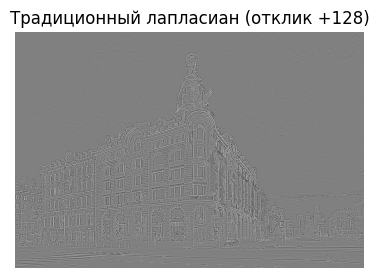

In [62]:
# Маски оператора Лапласа (коэффициенты заданы явно)
LAP_TRAD = np.array([[0, 1, 0],
                     [1, -4, 1],
                     [0, 1, 0]], dtype=float)
LAP_DIAG = np.array([[1, 0, 1],
                     [0, -4, 0],
                     [1, 0, 1]], dtype=float) / 2
LAP_COMB = np.array([[1, 1, 1],
                     [1, -8, 1],
                     [1, 1, 1]], dtype=float) / 3

L_trad = apply_mask(img, LAP_TRAD)
L_diag = apply_mask(img, LAP_DIAG)
L_comb = apply_mask(img, LAP_COMB)

show(L_trad, 'Традиционный лапласиан (отклик +128)', signed=True)

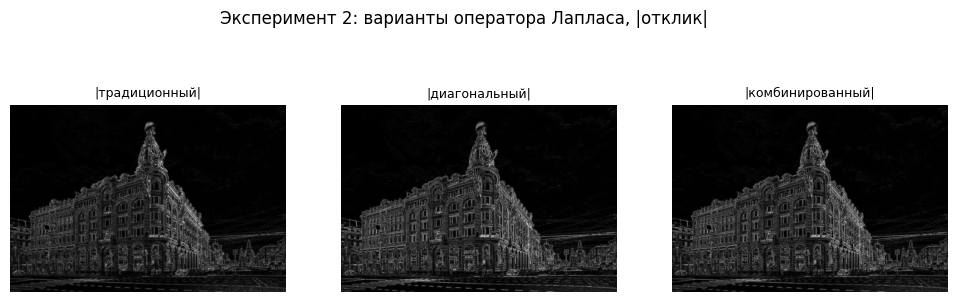

In [63]:
# Эксперимент 2: сравнение трёх масок (абсолютные значения отклика)
show_grid([np.abs(L_trad), np.abs(L_diag), np.abs(L_comb)],
          ['|традиционный|', '|диагональный|', '|комбинированный|'],
          'Эксперимент 2: варианты оператора Лапласа, |отклик|')

**Эксперимент 2, наблюдения.** Все три маски выделяют одни и те же перепады, но по-разному: диагональная реагирует на диагональные границы и игнорирует чисто горизонтальные/вертикальные «ступеньки» (и наоборот для традиционной); комбинированная реагирует на границы всех ориентаций, но даёт более «размытый» и более шумный отклик (больше ненулевых коэффициентов -> больше усиление шума, $Q=8$ против $Q=20$ у традиционной и $Q=5$ у диагональной). На плавных переходах яркости лапласиан даёт двойные контуры (два знаковых «флажка» по сторонам перепада).

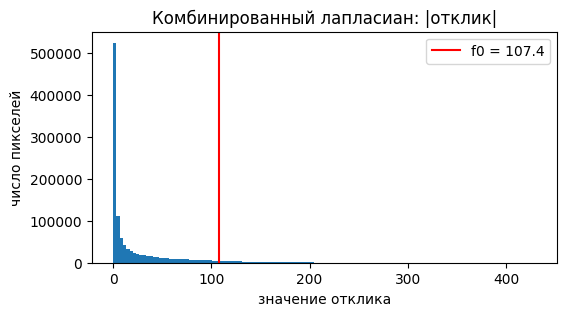

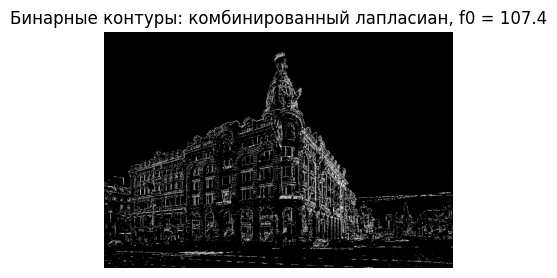

In [64]:
f0_lap = pick_threshold(np.abs(L_comb))
hist_and_threshold(np.abs(L_comb), f0_lap, 'Комбинированный лапласиан: |отклик|')
b_lap = binarize(np.abs(L_comb), f0_lap)
show(b_lap, f'Бинарные контуры: комбинированный лапласиан, f0 = {f0_lap:.1f}')

## 5. Оператор Прюитт (метод согласования)

Идея метода согласования — сглаживание (подгонка плоскости по МНК) перед дифференцированием. При аппроксимации плоскостью в окне $3\times3$ получаются две маски:

$$\tfrac{1}{6}\begin{pmatrix} -1 & -1 & -1\\ 0 & 0 & 0\\ 1 & 1 & 1 \end{pmatrix}, \qquad \tfrac{1}{6}\begin{pmatrix} -1 & 0 & 1\\ -1 & 0 & 1\\ -1 & 0 & 1 \end{pmatrix}.$$

С их помощью формируются промежуточные изображения $s_1(m,n)$ и $s_2(m,n)$, затем вычисляется модуль градиента $e(m,n)=\sqrt{s_1^2+s_2^2}$.

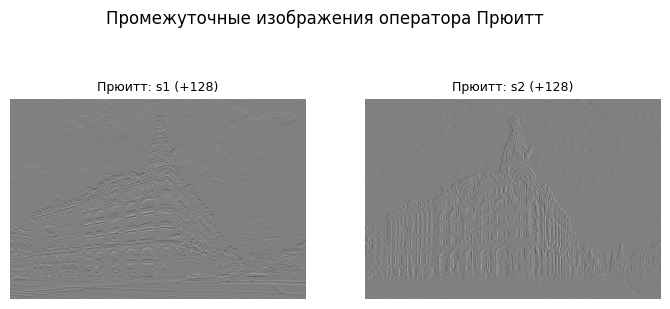

In [65]:
# Маски оператора Прюитт (коэффициенты заданы явно)
PREW_M = np.array([[-1, -1, -1],
                   [ 0,  0,  0],
                   [ 1,  1,  1]], dtype=float) / 6    # s1: разность по m
PREW_N = np.array([[-1, 0, 1],
                   [-1, 0, 1],
                   [-1, 0, 1]], dtype=float) / 6       # s2: разность по n


def prewitt_magnitude(image):
    """Оператор Прюитт: две маски -> s1, s2 -> модуль градиента."""
    s1_ = apply_mask(image, PREW_M)
    s2_ = apply_mask(image, PREW_N)
    return np.sqrt(s1_ ** 2 + s2_ ** 2)


p1 = apply_mask(img, PREW_M)
p2 = apply_mask(img, PREW_N)
show_grid([p1, p2], ['Прюитт: s1 (+128)', 'Прюитт: s2 (+128)'],
          'Промежуточные изображения оператора Прюитт', signed=True)

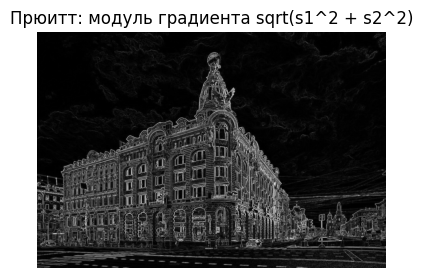

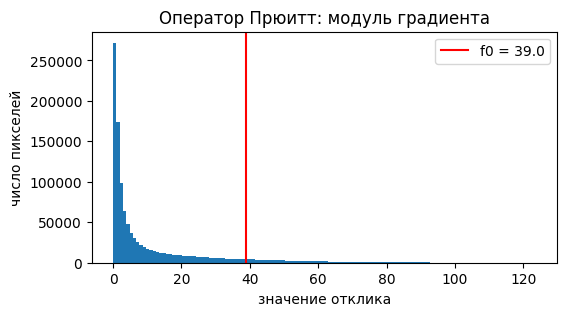

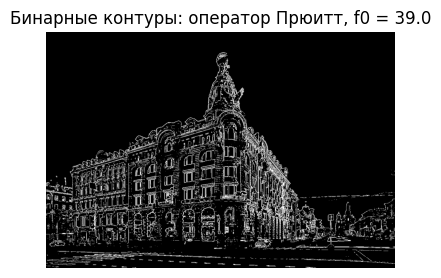

In [66]:
e_prew = prewitt_magnitude(img)
show(e_prew, 'Прюитт: модуль градиента sqrt(s1^2 + s2^2)')

f0_prew = pick_threshold(e_prew)
hist_and_threshold(e_prew, f0_prew, 'Оператор Прюитт: модуль градиента')
b_prew = binarize(e_prew, f0_prew)
show(b_prew, f'Бинарные контуры: оператор Прюитт, f0 = {f0_prew:.1f}')

## 6. Согласованный оператор Лапласа

При аппроксимации функции яркости поверхностью второго порядка в окне $3\times3$ получается согласованная маска лапласиана:

$$\tfrac{1}{3}\begin{pmatrix} 2 & -1 & 2\\ -1 & -4 & -1\\ 2 & -1 & 2 \end{pmatrix}.$$

Используется абсолютное значение отклика.

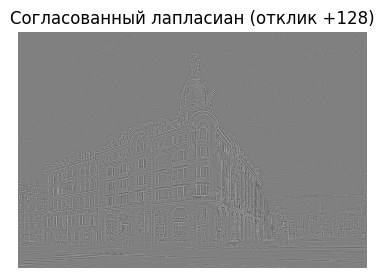

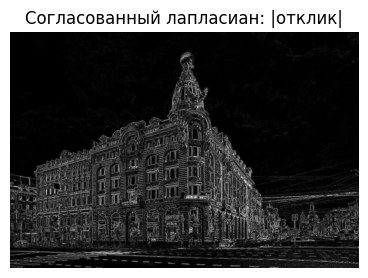

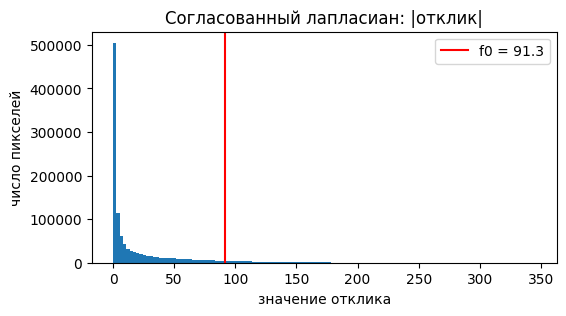

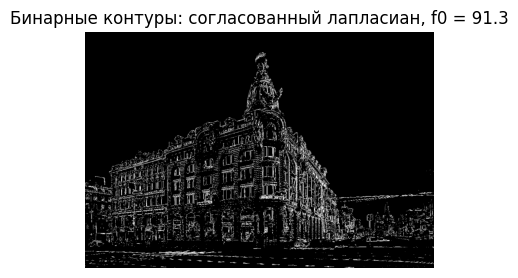

In [67]:
# Согласованный лапласиан (коэффициенты заданы явно)
LAP_MATCH = np.array([[ 2, -1,  2],
                      [-1, -4, -1],
                      [ 2, -1,  2]], dtype=float) / 3

L_match = apply_mask(img, LAP_MATCH)
show(L_match, 'Согласованный лапласиан (отклик +128)', signed=True)

e_match = np.abs(L_match)
show(e_match, 'Согласованный лапласиан: |отклик|')

f0_match = pick_threshold(e_match)
hist_and_threshold(e_match, f0_match, 'Согласованный лапласиан: |отклик|')
b_match = binarize(e_match, f0_match)
show(b_match, f'Бинарные контуры: согласованный лапласиан, f0 = {f0_match:.1f}')

## 7. Эксперимент 3. Сравнение итоговых результатов методов

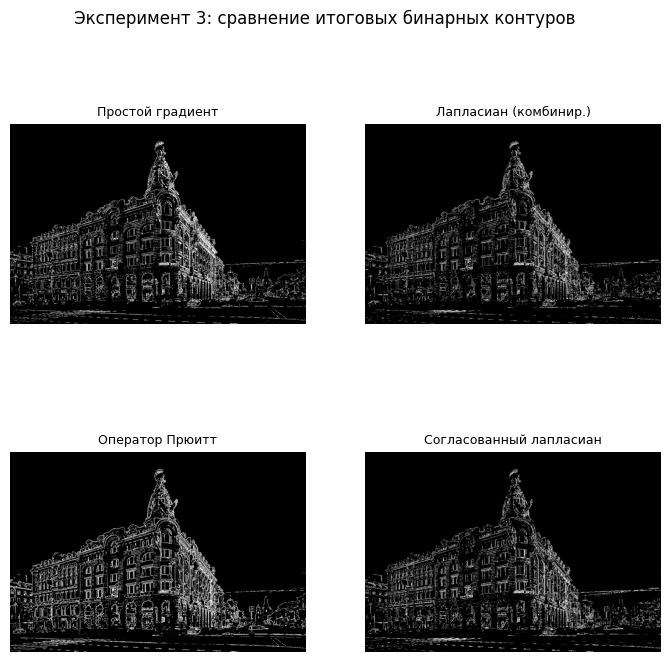

In [68]:
methods = {
    'Простой градиент':      (grad_magnitude, f0_grad, b_grad),
    'Лапласиан (комбинир.)': (lambda im: np.abs(apply_mask(im, LAP_COMB)), f0_lap, b_lap),
    'Оператор Прюитт':       (prewitt_magnitude, f0_prew, b_prew),
    'Согласованный лапласиан': (lambda im: np.abs(apply_mask(im, LAP_MATCH)), f0_match, b_match),
}
# methods[имя] = (функция промежуточного изображения, порог f0, бинарный результат)

show_grid([m[2] for m in methods.values()], list(methods.keys()),
          'Эксперимент 3: сравнение итоговых бинарных контуров', ncols=2)

**Эксперимент 3, наблюдения.** Простой градиент даёт самые тонкие контуры, но реагирует на каждый локальный перепад (шум/текстура). Лапласиан подчёркивает контуры всех ориентаций, но на плавных переходах контуры раздваиваются, а отклик более «зашумлён». Прюитт за счёт встроенного сглаживания даёт более гладкие и толстые контурные линии и меньше отклика на мелкий шум. Согласованный лапласиан визуально близок к комбинированному, но отклик чище (коэффициент усиления шума $Q=4$ против $Q=8$).

## 8. Эксперимент 4. Выбор порога

Для простого градиентного метода сравниваются бинарные изображения при заниженном, выбранном и завышенном пороге $f_0$.

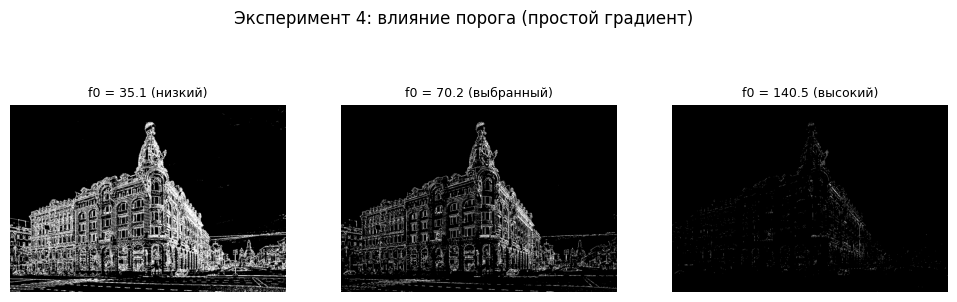

In [69]:
show_grid([binarize(e_exact, 0.5 * f0_grad), b_grad, binarize(e_exact, 2.0 * f0_grad)],
          [f'f0 = {0.5 * f0_grad:.1f} (низкий)',
           f'f0 = {f0_grad:.1f} (выбранный)',
           f'f0 = {2.0 * f0_grad:.1f} (высокий)'],
          'Эксперимент 4: влияние порога (простой градиент)')

**Эксперимент 4, наблюдения.** При слишком низком пороге контуры утолщаются, появляются ложные контуры от шума и слабых локальных неоднородностей. При слишком высоком пороге слабые перепады яркости теряются, контурные линии становятся прерывистыми (разрывы контуров).

## 9. Сравнение со стандартным детектором Canny (дополнительно)

**Важно:** Canny — готовая библиотечная реализация, приведена только для сравнения и не заменяет самостоятельную реализацию обязательных методов выше.

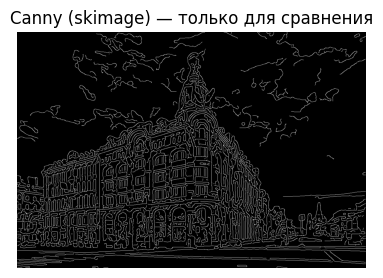

In [70]:
from skimage.feature import canny   # библиотечный детектор, только для сравнения

b_canny = canny(img, sigma=3.0, low_threshold=10, high_threshold=30).astype(np.uint8) * 255
show(b_canny, 'Canny (skimage) — только для сравнения')

## 10. Эксперимент 5. Устойчивость к шуму

К исходному изображению добавляется гауссов шум с $\sigma = 15$ (шум генерируется и добавляется вручную, для воспроизводимости зафиксировано начальное состояние генератора `seed = 42`). Затем к зашумлённому изображению применяются все методы с теми же масками и теми же порогами $f_0$, что и для исходного изображения.

Теоретический коэффициент усиления белого шума $Q=\sum\sum a^2(k,l)$:

| Маска | $Q$ |
|---|---:|
| Традиционный лапласиан | 20 |
| Диагональный лапласиан | 5 |
| Комбинированный лапласиан | 8 |
| Согласованный лапласиан | 4 |

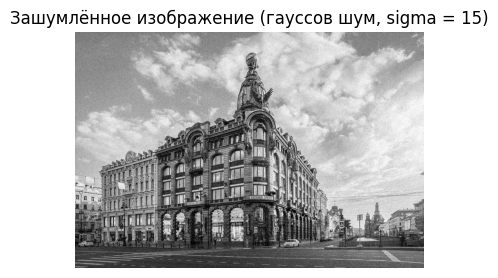

In [71]:
# Гауссов шум: sigma = 15, seed = 42 (добавление шума - вручную)
rng = np.random.default_rng(42)
noise = rng.normal(0.0, 15.0, size=img.shape)
img_noisy = np.clip(img + noise, 0.0, 255.0)
show(img_noisy, 'Зашумлённое изображение (гауссов шум, sigma = 15)')

метод                       контуров (чистое)  контуров (шум)  потеряно   ложных
Простой градиент                        80274          108002     12291    40019
Лапласиан (комбинир.)                   63669           93373     14806    44510
Оператор Прюитт                         94507           98757      8925    13175
Согласованный лапласиан                 69435           85662     14208    30435


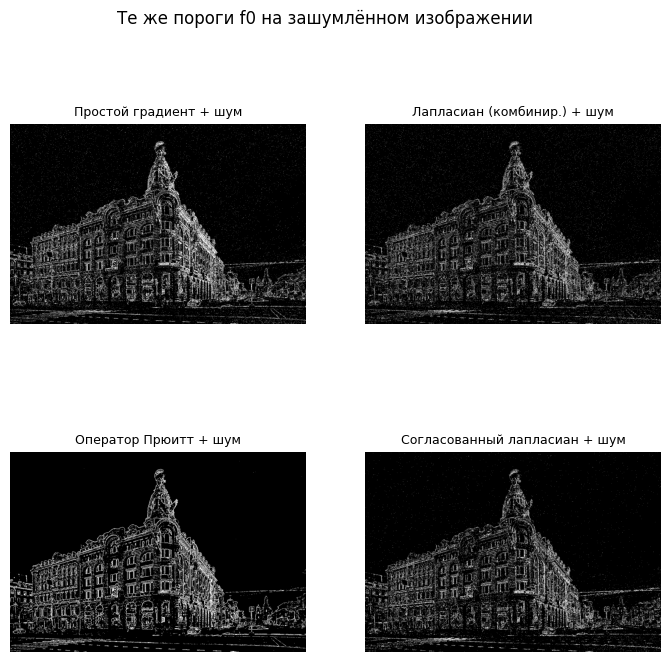

In [ ]:
# Применение всех методов с теми же порогами f0
noisy_binaries = []
stats = []
for name, (func, f0, b_clean) in methods.items():
    b_noisy = binarize(func(img_noisy), f0)
    noisy_binaries.append(b_noisy)
    lost = int(np.sum((b_clean == 255) & (b_noisy == 0)))      # потерянные контуры
    spurious = int(np.sum((b_clean == 0) & (b_noisy == 255)))  # ложные контуры
    stats.append((name, int((b_clean == 255).sum()), int((b_noisy == 255).sum()),
                  lost, spurious))

show_grid(noisy_binaries, [n + ' + шум' for n in methods],
          'Те же пороги f0 на зашумлённом изображении', ncols=2)

print(f'{"метод":26s} {"контуров (чистое)":>18s} {"контуров (шум)":>15s} '
      f'{"потеряно":>9s} {"ложных":>8s}')
for name, n_clean, n_noisy, lost, spurious in stats:
    print(f'{name:26s} {n_clean:18d} {n_noisy:15d} {lost:9d} {spurious:8d}')

**Эксперимент 5, наблюдения.**

- Больше всего ложных контуров даёт комбинированный лапласиан — наибольшее усиление шума среди исследуемых масок ($Q=8$; у традиционной, не вошедшей в итоговое сравнение, $Q=20$ — ещё хуже).
- Простой градиент занимает промежуточное положение: разностный оператор без сглаживания усиливает шум заметно сильнее метода согласования.
- Меньше всего ложных контуров дают методы согласования: оператор Прюитт (усреднение трёх отсчётов вдоль границы перед вычислением разности) и согласованный лапласиан ($Q=4$ против $Q=8$ у комбинированного — усиление шума вдвое меньше).
- Порядок числа ложных контуров согласуется с теоретическими значениями $Q=\sum\sum a^2(k,l)$: чем больше сумма квадратов коэффициентов маски, тем сильнее усиливается шум.
- Часть слабых исходных контуров теряется у всех методов: добавленный шум «размывает» перепад, и отклик опускается ниже фиксированного порога $f_0$.
- Наиболее устойчивым к шуму оказывается метод согласования.

## 11. Выводы

1. **Различия методов.** Простой градиент даёт тонкие одинарные контуры, но реагирует на любой локальный перепад. Лапласиан реагирует на границы всех ориентаций (комбинированная маска) или на избранные ориентации (традиционная — ортогональные, диагональная — диагональные границы), но даёт двойные контуры на плавных переходах и сильнее усиливает шум. Методы согласования (Прюитт, согласованный лапласиан) за счёт сглаживания в окне дают более устойчивые и гладкие контуры.
2. **Влияние маски.** Выбор коэффициентов определяет и чувствительность к ориентации границ, и усиление шума: $Q=\sum\sum a^2(k,l)$ растёт с числом и величиной коэффициентов (20 / 5 / 8 / 4 для традиционной, диагональной, комбинированной и согласованной масок лапласиана). Подтверждено экспериментом 5.
3. **Реакция на шум.** После добавления гауссова шума ($\sigma=15$) наибольшее число ложных контуров даёт комбинированный лапласиан ($Q=8$), промежуточное — простой градиент, наименьшее — согласованный лапласиан ($Q=4$) и Прюитт, что соответствует теории ($Q=\sum\sum a^2(k,l)$).
4. **Влияние порога.** Низкий порог: контуры толще, появляются ложные контуры от шума и неоднородностей. Высокий порог: разрывы контурных линий и потеря слабых перепадов яркости (эксперимент 4).
5. **Ложные контуры** возникают при низком пороге и/или при большом $Q$ маски на зашумлённом изображении; **разрывы контуров** — при высоком пороге, а также у лапласиана на плавных (нескачкообразных) изменениях яркости из-за раздваивания отклика.